
# CNN for Street View House Number Classification with Layer Visualizations
---

Prof. Dr.-Ing. Antje Muntzinger, Hochschule für Technik Stuttgart

antje.muntzinger@hft-stuttgart.de

---
This notebook trains a small CNN on the SVHN (Street View House Number) dataset. The dataset contains over 600k real-world images of house numbers from Google Street View images.  

<div style="display: flex; align-items: center; gap: 15px;">
    <img src="images/example1.png" style="height: 200px; width: auto;" />
    <img src="images/example2.png" style="height: 200px; width: auto;" />
    <img src="images/example3.png" style="height: 200px; width: auto;" />
</div>

We want to take a glimpse into the CNN internals and visualize the feature maps after the first and second convolution layer, as well as the learned filter weights. 


In [15]:
%pip install torch torchvision
%pip install requests
%pip install scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
# import necessary libraries
import os, random, math
import numpy as np
import torch
from torch import nn, optim
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, utils as vutils
import matplotlib.pyplot as plt
from pathlib import Path
import requests
import zipfile
import io

# Set random seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

## Train on GPU

Since these are larger (32x32x3) images, it may prove useful to speed up your training time by using a GPU. CUDA is a parallel computing platform and CUDA Tensors are the same as typical Tensors, only they utilize GPU's for computation.

In [17]:
# Check for GPU availability
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
train_on_gpu = torch.cuda.is_available()

if not train_on_gpu:
    print('CUDA is not available.  Training on CPU ...')
else:
    print('CUDA is available!  Training on GPU ...')

CUDA is not available.  Training on CPU ...


## Data Loading and Preprocessing

We use three separate splits of SVHN:
- **Training:** learn the model parameters.
- **Validation:** monitor learning and compare design choices.
- **Test:** evaluate the final model only after model choices are made.

The validation split is taken from the original SVHN training data. Both validation and test images use the training-set normalization statistics.


In [18]:
# Download SVHN dataset if not already present
data_dir = Path("./data")
data_dir.mkdir(parents=True, exist_ok=True)

train_file = data_dir / "train_32x32.mat"
test_file = data_dir / "test_32x32.mat"

# Download only if data is not already available
if not (train_file.exists() and test_file.exists()):
    try:
        # Try bwSync&Share first
        url = "https://bwsyncandshare.kit.edu/s/x82PAZ5ZDEGJDrw/download"
        response = requests.get(url, timeout=120)
        response.raise_for_status()

        # Extract ZIP archive
        with zipfile.ZipFile(io.BytesIO(response.content)) as z:
            for filename in ("train_32x32.mat", "test_32x32.mat"):
                with z.open(filename) as source:
                    (data_dir / filename).write_bytes(source.read())

        print("SVHN downloaded from bwSync&Share.")

    except (requests.RequestException, zipfile.BadZipFile,
            KeyError, OSError) as e:
        print("bwSync&Share download failed:", e)
        print("Trying Stanford instead...")

        datasets.SVHN(root=str(data_dir), split="train", download=True)
        datasets.SVHN(root=str(data_dir), split="test", download=True)

# Apply SVHN channel-wise normalization statistics (training set)
# Source: DeepOBS SVHN dataset implementation
# https://deepobs.readthedocs.io/en/v1.2.0-beta0_a/_modules/deepobs/pytorch/datasets/svhn.html
SVHN_MEAN = (0.4377, 0.4438, 0.4728)
SVHN_STD = (0.1980, 0.2010, 0.1970)

transform_train = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(SVHN_MEAN, SVHN_STD)
])
transform_test = transform_train

from torch.utils.data import random_split

full_train_set = datasets.SVHN(root=str(data_dir), split='train',
                               download=False, transform=transform_train)
test_set = datasets.SVHN(root=str(data_dir), split='test',
                         download=False, transform=transform_test)

n_valid = int(0.1 * len(full_train_set))
n_train = len(full_train_set) - n_valid
train_set, valid_set = random_split(
    full_train_set, [n_train, n_valid],
    generator=torch.Generator().manual_seed(42)
)

batch_size = 128
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=0)
valid_loader = DataLoader(valid_set, batch_size=batch_size, shuffle=False, num_workers=0)
test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False, num_workers=0)


print(f"Training set size: {len(train_set)} images")
print(f"Validation set size: {len(valid_set)} images")
print(f"Test set size: {len(test_set)} images")

Training set size: 65932 images
Validation set size: 7325 images
Test set size: 26032 images


Let's take a look at some images:

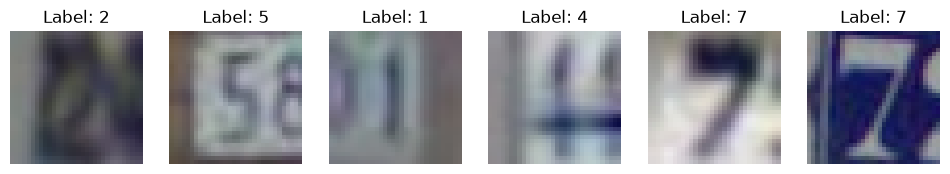

In [19]:
# Visualize some data
dataiter = iter(train_loader)
images, labels = dataiter.__next__()
fig, axes = plt.subplots(1, 6, figsize=(12,2))
for i in range(6):  
    img = images[i].numpy().transpose((1, 2, 0))
    img = img * np.array([0.1980, 0.2010, 0.1970]) + np.array([0.4377, 0.4438, 0.4728])  # unnormalize
    img = np.clip(img, 0, 1)
    axes[i].imshow(img)
    axes[i].set_title(f"Label: {labels[i].item()}")
    axes[i].axis('off')

## Define the Network [Architecture](http://pytorch.org/docs/stable/nn.html)

This time, you'll define a CNN architecture. Instead of an MLP, which used linear, fully-connected layers, you'll use the following:
* [Convolutional layers](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html#torch.nn.Conv2d), which can be thought of as stack of filtered images.
* [Maxpooling layers](https://pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html#torch.nn.MaxPool2d), which reduce the x-y size of an input, keeping only the most _active_ pixels from the previous layer.
* The usual Linear (fully connected) layers to produce a 10-dim output.

A network with 2 convolutional layers is shown in the image below and in the code, and you've been given starter code with two convolutional and two maxpooling layers.

<img src='images/2_layer_conv.png' width=80% />


In [20]:
# Define a small CNN
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 8, kernel_size=3, padding=1) # (3 input channels, 8 output channels, 3x3 kernel, padding=1)
        self.pool1 = nn.MaxPool2d(2,2) # 2x2 max pooling with stride 2
        self.conv2 = nn.Conv2d(8, 16, kernel_size=3, padding=1) # (8 input channels, 16 output channels, 3x3 kernel, padding=1)
        self.pool2 = nn.MaxPool2d(2,2) # 2x2 max pooling with stride 2
        self.fc1   = nn.Linear(16*8*8, 64) # fully connected layer
        self.fc2   = nn.Linear(64, 10) # output layer for 10 classes

    def forward(self, x, return_feats=False):
        # Input: 3x32x32
        x = F.relu(self.conv1(x))
        # Output: 8x32x32
        f1 = self.pool1(x)
        # Output: 8x16x16
        x = F.relu(self.conv2(f1))
        # Output: 16x16x16
        f2 = self.pool2(x)
        # Output: 16x8x8
        x = torch.flatten(f2, 1)
        # Output: 16*8*8
        x = F.relu(self.fc1(x))
        # Output: 64
        logits = self.fc2(x) # CrossEntropyLoss expects raw logits
        # Output: 10
        if return_feats: return logits, f1, f2 # return features for visualization
        return logits


# Initialize model, loss function, and optimizer
model = SmallCNN().to(device)
criterion = nn.CrossEntropyLoss() 
optimizer = optim.Adam(model.parameters(), lr=1e-3)


### Training the Network

Let's train our CNN by looping over all images and applying backpropagation for each batch of 128 images.


<img src='images/backprop.jpg' width=80% />

In [21]:
from time import time # measure the training time
start = time()

# Training and evaluation loop
def evaluate(model, loader, device):
    model.eval(); correct=total=0; loss_sum=0.0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device) 
            logits = model(images)
            loss = criterion(logits, labels)
            preds = logits.argmax(1)
            correct += (preds == labels).sum().item()
            total   += labels.size(0)
            loss_sum += loss.item() * labels.size(0)
    return correct/max(1,total), loss_sum/max(1,total)

epochs = 10 # number of training epochs
train_hist, valid_hist = [], []

# Loop over epochs
for epoch in range(1, epochs+1): 
    model.train()
    run_loss=0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device) # move to device

        # Perform training step - one forward and backward pass
        optimizer.zero_grad() # zero the gradients
        logits = model(images) # forward pass
        loss = criterion(logits, labels) # compute loss
        loss.backward(); # backpropagate
        optimizer.step() # update weights

        run_loss += loss.item() # accumulate loss

    # Evaluate on training and validation sets
    train_acc, train_loss = evaluate(model, train_loader, device)
    valid_acc, valid_loss   = evaluate(model, valid_loader, device)
    train_hist.append((train_loss, train_acc))
    valid_hist.append((valid_loss, valid_acc))
    print(f"Epoch {epoch:02d}/{epochs} | Train loss {train_loss:.4f}, accuracy {train_acc*100:.2f}% | "
          f"Validation loss {valid_loss:.4f}, accuracy {valid_acc*100:.2f}%")

# measure the training time
end = time()
print(f"Runtime training: {end - start:.2f} seconds")

# runtime on CPU: 2600 seconds = 43 minutes
# runtime on GPU (RTX 5070 Ti): 85 seconds

Epoch 01/10 | Train loss 0.6465, accuracy 81.04% | Validation loss 0.6919, accuracy 80.34%


KeyboardInterrupt: 

**TODO:** 1) Plot the training and validation loss and accuracy curves, respectively. How do you interpret the results? What would you suggest? **(4 points)**

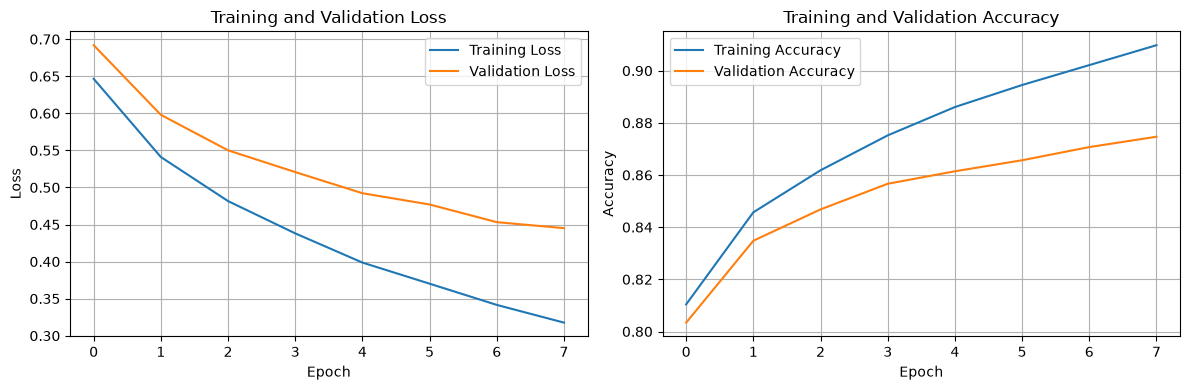

In [ ]:
# YOUR CODE HERE
# Extract loss and accuracy values
train_loss = [x[0] for x in train_hist]
train_acc = [x[1] for x in train_hist]

valid_loss = [x[0] for x in valid_hist]
valid_acc = [x[1] for x in valid_hist]

# Create the plots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot training and validation loss
axes[0].plot(train_loss, label="Training Loss")
axes[0].plot(valid_loss, label="Validation Loss")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid()

# Plot training and validation accuracy
axes[1].plot(train_acc, label="Training Accuracy")
axes[1].plot(valid_acc, label="Validation Accuracy")
axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()


**ANSWER:** 

## Interpretation and Layer Visualization

Now let's take a glimpse into the black box with a single test image. We visualize the features after each Convolution-ReLU-Pooling block. With `padding=1`, each 3 × 3 convolution preserves the spatial resolution; pooling halves it.

In [ ]:
# One validation image + feature maps
model.eval()
images, labels = next(iter(valid_loader))
img = images[0:1].to(device); label = labels[0].item()
with torch.no_grad():
    logits, conv1_maps, conv2_maps = model(img, return_feats=True)
    pred = logits.argmax(1).item()

# Denormalize for display
mean = torch.tensor([0.4377, 0.4438, 0.4728], device=device).view(1,3,1,1)
std  = torch.tensor([0.1980, 0.2010, 0.1970], device=device).view(1,3,1,1)
img_denorm = img * std + mean
img_np = img_denorm[0].detach().cpu().permute(1,2,0).numpy(); img_np = np.clip(img_np, 0, 1)

plt.figure(figsize=(3,3)); plt.imshow(img_np); plt.title(f"Input | true: {label}, pred: {pred}")
plt.axis('off'); plt.show()


We start by visualizing the feature maps in the first convolution layer:

In [ ]:
# Visualization helpers
import math
def plot_feature_maps_grid(feat, title_prefix="Feature map", max_maps=16):
    feat_np = feat[0].detach().cpu().numpy()
    C, H, W = feat_np.shape; n = min(C, max_maps)
    cols = int(math.sqrt(n) + 0.999); rows = int(math.ceil(n / cols))
    plt.figure(figsize=(2*cols, 2*rows))
    for i in range(n):
        plt.subplot(rows, cols, i+1)
        fm = feat_np[i]; fm = (fm - fm.min()) / (fm.max() - fm.min() + 1e-8)
        plt.imshow(fm, cmap='gray'); plt.title(f"{title_prefix} {i}"); plt.axis('off')
    plt.tight_layout(); plt.show()

In [ ]:
# Shape of the feature maps (after pooling)
print('conv1:', tuple(conv1_maps.shape))   # B x 8 x 16 x 16
print('conv2:', tuple(conv2_maps.shape))   # B x 16 x 8 x 8
plot_feature_maps_grid(conv1_maps, title_prefix="conv1", max_maps=8)

**TODO:** 2) Plot the feature maps of the second Convolution-ReLU-Pooling block. Compare spatial resolution and the number of channels: Which operation reduces spatial resolution, and which changes the number of channels? **(4 points)**

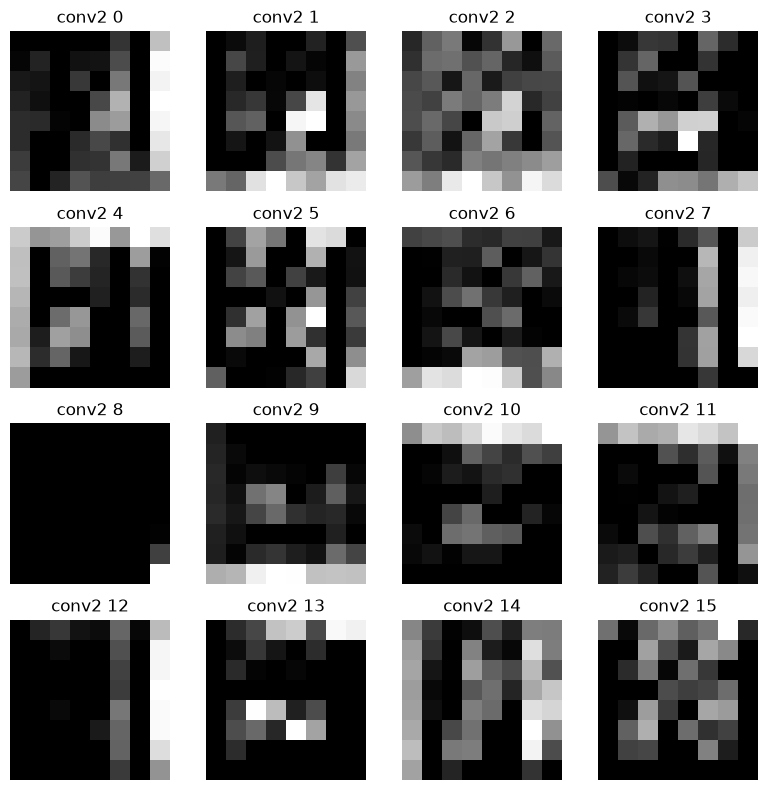

In [23]:
# YOUR CODE HERE
# Get feature maps from a validation image
model.eval()

images, labels = next(iter(valid_loader))
img = images[0:1].to(device)

with torch.no_grad():
    logits, conv1_maps, conv2_maps = model(img, return_feats=True)
    import math

def plot_feature_maps_grid(feat, title_prefix="Feature map", max_maps=16):
    feat_np = feat[0].detach().cpu().numpy()
    C, H, W = feat_np.shape
    n = min(C, max_maps)

    cols = int(math.sqrt(n) + 0.999)
    rows = int(math.ceil(n / cols))

    plt.figure(figsize=(2*cols, 2*rows))

    for i in range(n):
        plt.subplot(rows, cols, i+1)
        fm = feat_np[i]
        fm = (fm - fm.min()) / (fm.max() - fm.min() + 1e-8)
        plt.imshow(fm, cmap='gray')
        plt.title(f"{title_prefix} {i}")
        plt.axis('off')

    plt.tight_layout()
    plt.show()


# Visualize feature maps of the second convolutional block
plot_feature_maps_grid(conv2_maps, title_prefix="conv2", max_maps=16)



**ANSWER:** 

Now let's visualize the learned filter weights to see what each filter responds to:

In [ ]:
# Visualize first-layer conv filters by channel (R/G/B separately)

w = model.conv1.weight.detach().cpu().numpy()  # [n_filters, 3, 3, 3]
n_filters = w.shape[0]
cols = 4   # 1x RGB + 3x channels
rows = n_filters

plt.figure(figsize=(2.5 * cols, 2 * rows))

for i in range(n_filters):
    k = w[i]  # [3,3,3]
    k_min, k_max = k.min(), k.max()
    k_norm = (k - k_min) / (k_max - k_min + 1e-8)
    k_rgb = np.transpose(k_norm, (1, 2, 0))

    # Combined RGB
    plt.subplot(rows, cols, i * cols + 1)
    plt.imshow(k_rgb)
    plt.title(f"Filter {i}\nRGB mix")
    plt.axis("off")

    # Individual channels
    for c, name in enumerate(["Red", "Green", "Blue"], start=1):
        plt.subplot(rows, cols, i * cols + c + 1)
        plt.imshow(k_norm[c-1], cmap="gray", vmin=0, vmax=1)
        plt.title(name)
        plt.axis("off")

plt.suptitle("conv1 filters (RGB + channels)", y=1.02)
plt.tight_layout()
plt.show()


It looks like filter 3 has leared to detect transitions from dark to light (left to right). Let's try it out on a synthetic image and analyse the result!

In [ ]:
def visualize_cnn_features(model, img, device='cpu', n_maps=8, title='Input image'):
    """
    Apply a CNN to an input image and visualize the first-layer feature maps.

    Args:
        model: CNN model that returns (output, feat1, feat2, ...) when called with return_feats=True
        img: torch.Tensor or np.ndarray, shape (3,H,W) or (1,3,H,W)
        device: 'cpu' or 'cuda'
        n_maps: number of feature maps to display
        title: title for input image plot
    """

    # Ensure shape (1,3,H,W)
    if img.ndim == 3:
        img = img.unsqueeze(0)
    img = img.to(device, dtype=torch.float32)

    # Forward pass
    mean = torch.tensor(SVHN_MEAN, device=device).view(1, 3, 1, 1)
    std = torch.tensor(SVHN_STD, device=device).view(1, 3, 1, 1)
    img_normalized = (img - mean) / std

    model.eval()
    with torch.no_grad():
        outputs = model(img_normalized, return_feats=True)
        if isinstance(outputs, tuple):
            _, f1, f2 = outputs
        else:
            raise ValueError("Model must return (out, feat1, feat2, ...) with return_feats=True")

    # === Plot input image ===
    fig, ax = plt.subplots(figsize=(3,3))
    ax.imshow(img[0].permute(1,2,0).cpu(), vmin=0, vmax=1)
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_edgecolor('black')
        spine.set_linewidth(1)
    fig.suptitle(f"Input image – {title}", fontsize=12)
    plt.show()

    # === Plot conv1 feature maps ===
    f1_np = f1[0].cpu().numpy()
    n_maps = min(n_maps, f1_np.shape[0])
    cols = 4
    rows = math.ceil(n_maps / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(2*cols, 2*rows))

    # Flatten 2D axes array for easy indexing
    axes = axes.flatten()

    for i in range(n_maps):
        fm = f1_np[i]
        fm = (fm - fm.min()) / (fm.max() - fm.min() + 1e-8)
        ax = axes[i]
        ax.imshow(fm, cmap='gray')
        ax.set_title(f"FM {i}", fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])

        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_edgecolor('black')
            spine.set_linewidth(1)

    # Turn off unused subplots
    for j in range(n_maps, len(axes)):
        axes[j].axis('off')

    fig.suptitle(f"conv1 activations – {title}", fontsize=12)
    plt.tight_layout()
    plt.show()


In [ ]:
# Generate synthetic test patterns with sharp intensity or color transitions
size = 32
img = torch.zeros(3, size, size)
img[:, :, 32//2:] = 1.0
visualize_cnn_features(model, img, device=device, title='gray vertical')

Our suggestion was right, filter 3 responds most strongly to the vertical edge! 

**TODO:** 3) Now it's your turn! Find out which filter responds to horizontal edges: Create a similar test image like above and visualize the features. **(4 points)**

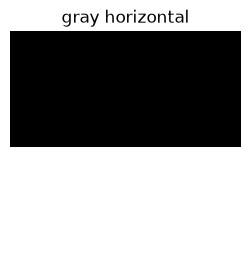

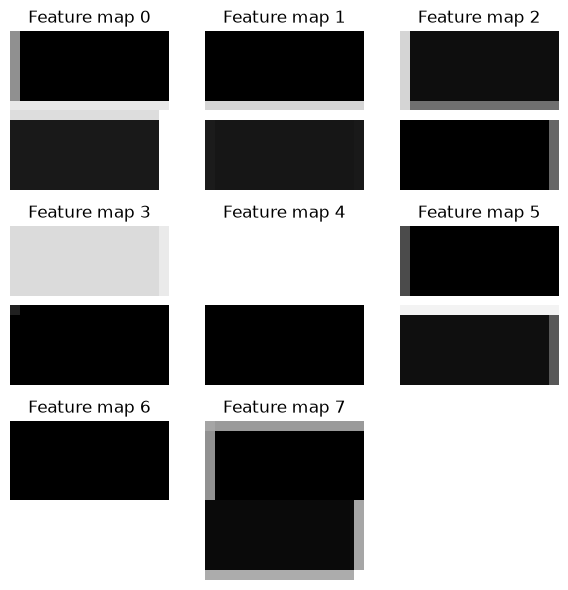

In [25]:
# YOUR CODE HERE
# Generate a synthetic image with a horizontal edge
# Function to visualize CNN features
def visualize_cnn_features(model, img, device='cpu', n_maps=8, title='Input image'):
    if img.dim() == 3:
        img = img.unsqueeze(0)

    img = img.to(device)

    mean = torch.tensor(SVHN_MEAN, device=device).view(1, 3, 1, 1)
    std = torch.tensor(SVHN_STD, device=device).view(1, 3, 1, 1)
    img_normalized = (img - mean) / std

    model.eval()
    with torch.no_grad():
        outputs = model(img_normalized, return_feats=True)
        _, f1, f2 = outputs

    img_np = img[0].detach().cpu().permute(1, 2, 0).numpy()
    img_np = np.clip(img_np, 0, 1)

    plt.figure(figsize=(3, 3))
    plt.imshow(img_np)
    plt.title(title)
    plt.axis('off')
    plt.show()

    plot_feature_maps_grid(f1, title_prefix="Feature map", max_maps=n_maps)


# Generate a synthetic image with a horizontal edge
size = 32
img = torch.zeros(3, size, size)
img[:, 32//2:, :] = 1.0

# Visualize the CNN features
visualize_cnn_features(model, img, device=device, title='gray horizontal')


**ANSWER:** 


**TODO:** 4) Which filter responds to diagonal edges? Create a similar test image like above and visualize the features. **(4 points)**

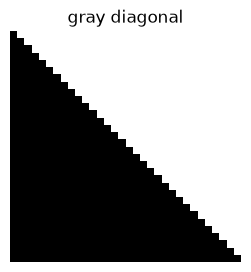

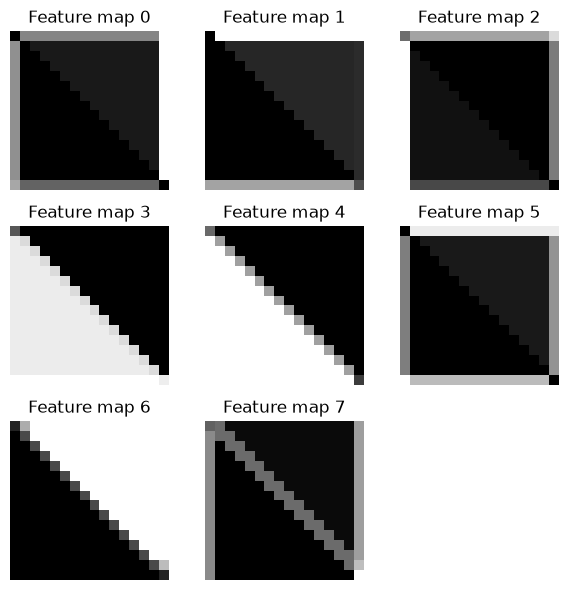

In [26]:
# YOUR CODE HERE
# Generate a synthetic image with a diagonal edge
size = 32
img = torch.zeros(3, size, size)

for i in range(size):
    for j in range(size):
        if j > i:
            img[:, i, j] = 1.0

# Visualize the CNN features
visualize_cnn_features(model, img, device=device, title='gray diagonal')


**ANSWER:** 


**TODO:** 5) Finally, take a look at the filter weights above. Any idea which filter responds to which color transitions (e.g., green on the left, blue on the right)? Create test images with color transitions and visualize the features. Find at least two different filters that respond to color transitions. **(6 points)**

**HINT:** Remember that filters react to similar patterns like their weights, comparable to template matching. 

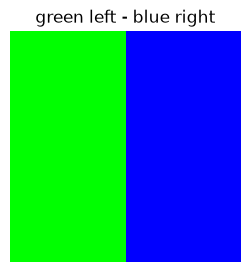

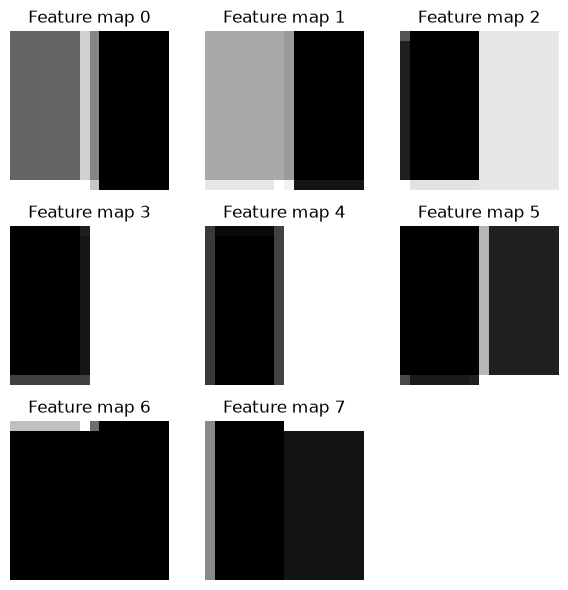

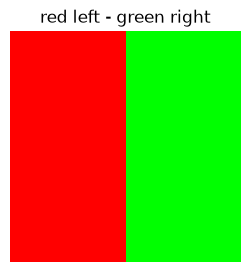

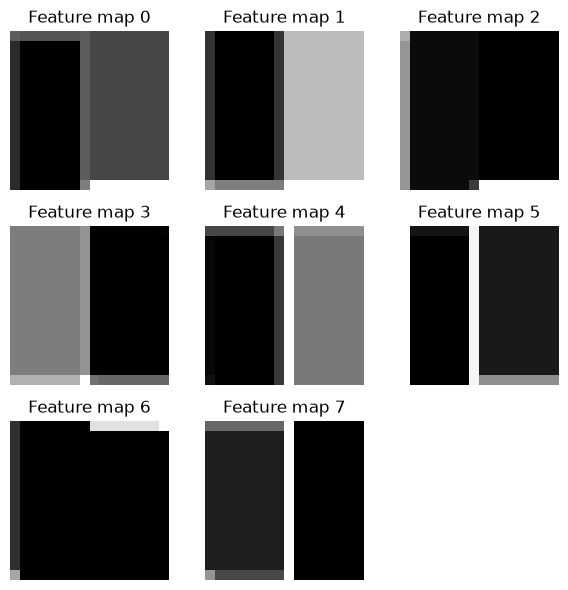

In [27]:
# YOUR CODE HERE
# Generate synthetic images with color transitions
size = 32

# Image 1: green on the left, blue on the right
img1 = torch.zeros(3, size, size)
img1[1, :, :size//2] = 1.0  # Green on the left
img1[2, :, size//2:] = 1.0  # Blue on the right

# Visualize the first color transition
visualize_cnn_features(
    model, img1, device=device,
    title='green left - blue right'
)

# Image 2: red on the left, green on the right
img2 = torch.zeros(3, size, size)
img2[0, :, :size//2] = 1.0  # Red on the left
img2[1, :, size//2:] = 1.0  # Green on the right

# Visualize the second color transition
visualize_cnn_features(
    model, img2, device=device,
    title='red left - green right'
)


**ANSWER:** 

To sum it up: with the padding used here, convolution preserves spatial resolution while learning new feature channels, whereas pooling reduces the spatial size without changing the channel count. Early convolution filters often respond to simple patterns such as edges and color transitions. Deeper layers can combine such patterns into higher-level representations. Note that interpretations of individual filters are qualitative and depend on the trained model and random seed.

## Design and Improve Your Own CNN

Now it's your turn! Design, train, and evaluate your own CNN for the SVHN digit-classification problem. The goal is to improve over the baseline if possible and to provide a convincing analysis, including if your model performs worse.

### Establish a baseline 

Before changing the architecture, we record the original `SmallCNN`'s final training and validation accuracy. We will compare candidate models using the validation data.

**TODO:** 6) Why do we not use test accuracy at this point? **(2 points)** 

**ANSWER:** 
We do not use test accuracy at this point because the test set must remain independent and unseen during model development. We use the validation set to compare different architectures and choose the best model. The test set is used only at the end to obtain an unbiased evaluation of the final model. Using test accuracy repeatedly could lead to overfitting to the test set.


We print the original model's final validation accuracy and parameter count and record them as your baseline:

In [ ]:
# baseline (example solution)
baseline_train_acc = train_hist[-1][1]
baseline_valid_acc = valid_hist[-1][1]
baseline_params = sum(p.numel() for p in model.parameters())
print(f"SmallCNN | train accuracy: {baseline_train_acc:.2%} | "
      f"validation accuracy: {baseline_valid_acc:.2%} | "
      f"parameters: {baseline_params:,}")

### Design a larger CNN 

**TODO:** 7) Implement your own CNN! Your new CNN must include:
- At least three convolutional layers, ReLU activations, and pooling.
- A classification head producing 10 logits, one for each digit.
- A working `forward()` method, including the transition from 2D feature maps to the classifier.

Before implementing it, complete the layer-shape table for your architecture below. **(8 points)**



**ANSWER:**

| Layer | Output shape (C × H × W) | Number of learnable parameters |
|---|---|---|
| Input | $3 \times 32 \times 32$ | 0 |
| Conv + ReLU 1 |... | ... |
| Pool 1 | ... | ... |
| Conv + ReLU 2 | ... | ... |
| Pool 2 | ... | ... |
| Conv + ReLU 3 | ... | ... |
| Flatten | ... | ... |
| FC + ReLU | ... | ... |
| FC (Output) | ... | ... |




In [ ]:
# YOUR CODE HERE  

### Train and improve your CNN 

**TODO:** 8) Train your CNN using a smaller learning rate than before. Print validation accuracy to choose your best candidate; also inspect train/validation loss for signs of overfitting. **(8 points)**

In [ ]:
# YOUR CODE HERE


**TODO:** 9) Plot the train/validation accuracy curves for your own model and report the final validation accuracy and number of parameters. If you are not satisfied, go back and improve your CNN, e.g. by adding more layers, changing the learning rate, or adding dropout. **(4 points)**

In [ ]:
# YOUR CODE HERE 

## Final test evaluation and discussion

**TODO:** 10) When you have selected the best candidate using validation results, compare it with the original `SmallCNN` on the held-out test set. Explain whether the larger CNN improved test accuracy, and discuss what else you could try in a future experiment. **(4 points)**

In [ ]:
# YOUR CODE HERE

**ANSWER:** 